# 02 — Data Cleaning (Làm sạch dữ liệu)

> Tiếp nối `01_eda.ipynb`. Notebook này làm sạch `train.csv` (Bank Marketing, `sep=';'`)
> trước khi đưa logic vào `src/data/preprocessing.py`.

Checklist 8 bước cleaning sẽ làm trong notebook này:
0. Setup môi trường (cell dưới) — chạy được Colab + local  
1. Load chuẩn (`sep=';'`)  
2. Chuẩn hoá chuỗi  
3. De-duplicate  
4. Xử lý bộ ba `pdays / previous / poutcome` (`-1` → `NaN` + `contacted_before`)  
5. Giữ `"unknown"` như 1 category  
6. Outlier (quan sát, không xoá)  
7. Kiểu dữ liệu & `y` → 0/1  
8. Validation & lưu `data/interim/`


## 0. Setup môi trường

> Bản setup chạy được trên **Colab** lẫn **local**, giữ cùng thứ tự import với `01_eda.ipynb` để dễ đối chiếu.
> Trên Colab nếu cần mount Drive thì bỏ comment 2 dòng `drive.mount` ở cell code.


In [10]:
# ============================================================
# 02_preprocessing - Buoc 0: Setup moi truong (Colab + local)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    display = print  # fallback khi chay .py thu`n

# --- hien thi ---
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.3f}'.format)

print(f"pandas {pd.__version__} | numpy {np.__version__}")

# --- Mount Google Drive (chi can tren Colab, local thi bo qua) ---
from google.colab import drive
drive.mount('/content/drive')

# --- Tim DATA_PATH tu dong: Colab trước, local sau ---
CANDIDATES = [
    Path("/content/drive/MyDrive/my_ds_project/data/raw/train.csv"),  # Colab
    Path("../data/raw/train.csv"),                                      # chay tu notebooks/
    Path("my_ds_project/data/raw/train.csv"),                           # chay tu repo root tren Colab
    Path("data/raw/train.csv"),                                         # chay tu my_ds_project/
    Path("C:/Users/Admin/Desktop/RandomForest_AdaBoost/my_ds_project/data/raw/train.csv"),  # local tuyet doi (Windows)
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[1])
DATA_DIR = DATA_PATH.parent
INTERIM_DIR = DATA_DIR.parent / "interim"   # data/interim/
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

print(f"DATA_PATH  = {DATA_PATH}  (exists={DATA_PATH.exists()})")
print(f"DATA_DIR   = {DATA_DIR}")
print(f"INTERIM_DIR= {INTERIM_DIR}")

# --- Kiem tra nhanh file ton tai & thu doc 1 dong de bat loi sep ---
if DATA_PATH.exists():
    preview = pd.read_csv(DATA_PATH, sep=';', nrows=3)
    print(f"Preview OK: shape(3 rows)={preview.shape}, columns={list(preview.columns)}")
    assert list(preview.columns) == ['age','job','marital','education','default','balance','housing','loan','contact','day','month','duration','campaign','pdays','previous','poutcome','y'], "Sai header - kiem tra lai sep=';' va file train.csv"
    print("Header hop le (17 cot, dung thu tu).")
else:
    print("CHUA tim thay train.csv - kiem tra lai duong dan tren.")

# --- Hang so dung chung cho cac buoc sau ---
CAT_COLS = ['job','marital','education','default','housing','loan','contact','month','poutcome']
NUM_COLS = ['age','balance','day','duration','campaign','pdays','previous']
TARGET   = 'y'
print(f"CAT_COLS={CAT_COLS}")
print(f"NUM_COLS={NUM_COLS}")


pandas 2.2.3 | numpy 2.1.3
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_PATH  = /content/drive/MyDrive/my_ds_project/data/raw/train.csv  (exists=True)
DATA_DIR   = /content/drive/MyDrive/my_ds_project/data/raw
INTERIM_DIR= /content/drive/MyDrive/my_ds_project/data/interim
Preview OK: shape(3 rows)=(3, 17), columns=['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']
Header hop le (17 cot, dung thu tu).
CAT_COLS=['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
NUM_COLS=['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


> ✅ Xong bước 0. Chạy cell trên phải thấy `Preview OK` và `Header hợp lệ` thì mới sang Bước 1.
> Các bước tiếp theo sẽ dùng `DATA_PATH`, `CAT_COLS`, `NUM_COLS`, `TARGET` đã định nghĩa ở đây.


## 1. Load chuẩn & chuẩn hoá chuỗi

> **Mục tiêu:** đọc toàn bộ `train.csv` đúng `sep=';'`, tách `df_raw` (bản gốc bất biến) và `df` (bản làm sạch ghi đè qua các bước), chuẩn hoá chuỗi để `"Unknown"`/`" unknown "` không thành 2 category khác nhau.
>
> **Kết quả lưu ở đâu?** Chỉ trong RAM (`df` / `df_raw`). **Không ghi ra file** ở bước này — chỉ ghi 1 lần ở Bước 8 ra `data/interim/train_clean.csv`.


In [11]:
# ============================================================
# Buoc 1: Load chuan & chuan hoa chuoi
# - df_raw: ban goc bat bien (doi chieu)
# - df    : ban lam sach, ghi de noi tiep qua cac buoc 1->7
# - chua luu ra file o buoc nay (chi luu o Buoc 8)
# ============================================================

# 1a. Load toan bo file (khac preview 3 dong o Buoc 0)
df_raw = pd.read_csv(DATA_PATH, sep=';', encoding='utf-8')
df_raw.columns = df_raw.columns.str.strip()  # chong " y " vs "y"
print(f"df_raw shape: {df_raw.shape}")  # ky vong (45211, 17)
print(f"Columns: {list(df_raw.columns)}")
display(df_raw.head(3))

# 1b. Tao ban lam viec
df = df_raw.copy()
print(f"df (ban lam sach) khoi tao: {df.shape} - id(df)!=id(df_raw): {id(df)!=id(df_raw)}")

# 1c. Chuan hoa chuoi: strip + lower cho toan bo cot categorical + target
# Ly do: tranh "Unknown" vs "unknown" thanh 2 category khi OneHot fit train/test
CAT_COLS_Y = CAT_COLS + [TARGET]
for c in CAT_COLS_Y:
    df[c] = df[c].astype(str).str.strip().str.lower()

print("--- Sau chuan hoa (strip + lower) ---")
for c in CAT_COLS_Y:
    vals = sorted(df[c].unique())
    preview = vals[:6]
    suffix = " ..." if len(vals) > 6 else ""
    print(f"{c:12s}: {len(vals):2d} unique -> {preview}{suffix}")

# 1d. Kiem tra nhanh: khong con chu hoa / khoang trang thua
for c in CAT_COLS_Y:
    assert (df[c].str.lower() == df[c]).all(), f"{c} van con chu hoa"
    assert (df[c].str.strip() == df[c]).all(), f"{c} van con space thua"
print("Assert chuan hoa OK (khong con chu hoa / space thua).")

# 1e. Kiem tra "unknown" van duoc GIU lai (chua fill/xoa o buoc nay)
print(" --- Ty le 'unknown' sau chuan hoa (van giu lai, chua xu ly) ---")
for c in ['job','education','contact','poutcome']:
    cnt = (df[c] == 'unknown').sum()
    print(f"{c:12s}: {cnt:5d} ({cnt/len(df)*100:4.1f}%)")

# 1f. Idempotent: chay lai lan nua ket qua khong doi
df_check = df.copy()
for c in CAT_COLS_Y:
    df_check[c] = df_check[c].astype(str).str.strip().str.lower()
assert df_check.equals(df), "Chuan hoa khong idempotent"
print("Idempotent OK: chay lai lan 2 khong doi ket qua.")
 
print(f"Buoc 1 xong. df shape: {df.shape} (trong RAM, chua luu ra file)")
print("df_raw giu nguyen de doi chieu, df se duoc ghi de tiep o Buoc 2->7.")


df_raw shape: (45211, 17)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no


df (ban lam sach) khoi tao: (45211, 17) - id(df)!=id(df_raw): True
--- Sau chuan hoa (strip + lower) ---
job         : 12 unique -> ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired'] ...
marital     :  3 unique -> ['divorced', 'married', 'single']
education   :  4 unique -> ['primary', 'secondary', 'tertiary', 'unknown']
default     :  2 unique -> ['no', 'yes']
housing     :  2 unique -> ['no', 'yes']
loan        :  2 unique -> ['no', 'yes']
contact     :  3 unique -> ['cellular', 'telephone', 'unknown']
month       : 12 unique -> ['apr', 'aug', 'dec', 'feb', 'jan', 'jul'] ...
poutcome    :  4 unique -> ['failure', 'other', 'success', 'unknown']
y           :  2 unique -> ['no', 'yes']
Assert chuan hoa OK (khong con chu hoa / space thua).
 --- Ty le 'unknown' sau chuan hoa (van giu lai, chua xu ly) ---
job         :   288 ( 0.6%)
education   :  1857 ( 4.1%)
contact     : 13020 (28.8%)
poutcome    : 36959 (81.7%)
Idempotent OK: chay lai lan 2 khong doi ket q

> ✅ Xong Bước 1. `df_raw` giữ nguyên, `df` đã chuẩn hoá chuỗi và vẫn nằm trong RAM.
> Chưa có file nào ghi ra `data/interim/` — chỉ ghi 1 lần ở Bước 8 sau khi xong cả 8 bước.
> Sang Bước 2: De-duplicate (`df.duplicated()`).


## 2. De-duplicate (loại dòng trùng)

> **Mục tiêu:** đảm bảo không có dòng trùng lặp làm lệch tần suất của RF / trọng số của AdaBoost.
> Với bộ này EDA cho thấy `duplicated()==0`, nhưng pipeline vẫn phải có bước này để an toàn khi dữ liệu production bị join trùng.
>
> **Lưu ở đâu?** Vẫn chỉ trong RAM — `df` bị ghi đè, chưa ghi ra file.


In [12]:
# ============================================================
# Buoc 2: De-duplicate
# - chi ghi de df trong RAM, chua luu ra file
# ============================================================

shape_before = df.shape
n_dup = df.duplicated().sum()
n_dup_subset = df.duplicated(subset=[c for c in df.columns if c != TARGET]).sum()  # phong truong hop y khac nhau
print(f"Shape truoc dedup : {shape_before}")
print(f"So dong trung hoan toan (toan bo 17 cot): {n_dup}")
print(f"So dong trung neu bo qua target y        : {n_dup_subset}")

if n_dup > 0:
    print(f"Phat hien {n_dup} dong trung -> hien thi 3 dong dau:")
    display(df[df.duplicated(keep=False)].head(3))
    df = df.drop_duplicates()
    print(f"Da drop_duplicates -> shape sau: {df.shape}")
else:
    print("Khong co dong trung hoan toan - giu nguyen df.")
    # van goi drop_duplicates de pipeline dong nhat (idempotent, khong doi shape)
    df = df.drop_duplicates()

# Kiem tra sau dedup
assert df.duplicated().sum() == 0, "Van con duplicate sau khi drop"
print(f"Assert OK: duplicated==0, shape hien tai: {df.shape}")
print(f"So dong da xoa: {shape_before[0] - df.shape[0]}")

# Idempotent: chay lai lan nua khong doi
shape_check = df.drop_duplicates().shape
assert shape_check == df.shape, "Dedup khong idempotent"
print("Idempotent OK: chay lai drop_duplicates khong doi shape.")


Shape truoc dedup : (45211, 17)
So dong trung hoan toan (toan bo 17 cot): 0
So dong trung neu bo qua target y        : 0
Khong co dong trung hoan toan - giu nguyen df.
Assert OK: duplicated==0, shape hien tai: (45211, 17)
So dong da xoa: 0
Idempotent OK: chay lai drop_duplicates khong doi shape.


> ✅ Xong Bước 2. `df` vẫn trong RAM, `duplicated()==0`, shape không đổi (bộ này không có trùng).
> Sang Bước 3: xử lý bộ ba `pdays / previous / poutcome`.


## 3. Xử lý sentinel `pdays / previous / poutcome` (QUAN TRỌNG NHẤT)

> **Mục tiêu:** tách thông tin *"đã từng liên hệ chưa"* ra khỏi giá trị số `pdays`.
> Trong Bank Marketing, `pdays=-1`, `previous=0`, `poutcome='unknown'` là **cùng 1 quần thể** — sentinel *"chưa từng liên hệ"*, không phải số ngày.
> Nếu để `-1` thì `mean/scaler` bị kéo lệch và `RF` sẽ học luật giả `pdays < 0`.
>
> **Thứ tự bắt buộc:** (1) tạo `contacted_before` → (2) đổi `-1` → `NaN` → (3) đồng bộ `poutcome`.
> **TUYỆT ĐỐI KHÔNG** `replace(-1, 999)` hay `fillna(0)` — sẽ làm RF hiểu nhầm `999` là "rất lâu" hoặc `0` là "vừa liên hệ hôm qua".
>
> **Lưu ở đâu?** Vẫn chỉ trong RAM — `df` bị ghi đè thêm cột `contacted_before`, chưa ghi ra file.


In [13]:
# ============================================================
# Buoc 3: Xu ly sentinel pdays / previous / poutcome
# - pdays==-1 la sentinel "chua tung lien he", KHONG phai so ngay thuc
# - previous==0 & poutcome=='unknown' tuong ung cung quan the nay
# - Thu tu BAT BUOC: tao contacted_before -> doi -1 thanh NaN -> dong bo poutcome
# ============================================================

# 3a. Thong ke truoc xu ly — de thay ro 3 cot dong bien
print("=== Truoc xu ly (df hien tai shape:", df.shape, ") ===")
n_minus1 = (df['pdays'] == -1).sum()
n_prev0  = (df['previous'] == 0).sum()
n_unk    = (df['poutcome'] == 'unknown').sum()
print(f"pdays==-1          : {n_minus1:5d} ({n_minus1/len(df)*100:5.2f}%)")
print(f"previous==0        : {n_prev0:5d} ({n_prev0/len(df)*100:5.2f}%)")
print(f"poutcome=='unknown': {n_unk:5d} ({n_unk/len(df)*100:5.2f}%)")
print(f"pdays.describe (bao gom -1):\n{df['pdays'].describe().to_string()}")
print()
# Bang cheo pdays==-1 vs poutcome — phai dong nhat gan 100%
ct = pd.crosstab(df['pdays'] == -1, df['poutcome'], margins=False)
print("Crosstab (pdays==-1) x poutcome:")
display(ct)

# 3b. Tao feature nhi phan TRUOC khi dung vao -1
# Ly do: sau khi replace -1 -> NaN thi khong con cach phan biet NaN nao la sentinel goc
# contacted_before = 0: chua tung lien he, 1: da tung lien he
if 'contacted_before' not in df.columns:
    df['contacted_before'] = (df['pdays'] != -1).astype(int)
    print(f"\nDa tao 'contacted_before': 0={(df['contacted_before']==0).sum()} ({(df['contacted_before']==0).mean()*100:.1f}%), 1={(df['contacted_before']==1).sum()} ({(df['contacted_before']==1).mean()*100:.1f}%)")
else:
    print(f"\n'contacted_before' da ton tai — giu nguyen: 0={(df['contacted_before']==0).sum()}, 1={(df['contacted_before']==1).sum()}")

# 3c. Doi -1 thanh NaN — de khong bi tinh vao mean/scaler sau nay
# KHONG lam: replace(-1, 999) hay fillna(0) — se lam RF hieu nham -1 la gia tri nho nhat
n_before = df['pdays'].isna().sum()
df['pdays'] = df['pdays'].replace(-1, np.nan)
n_after = df['pdays'].isna().sum()
print(f"pdays: NaN truoc={n_before}, sau replace(-1->NaN)={n_after} (tang {n_after-n_before}, phai == so dong pdays==-1 ban dau = {n_minus1})")
print(f"pdays.describe (sau khi NaN, bo qua NaN):\n{df['pdays'].describe().to_string()}")

# 3d. Dong bo poutcome: unknown khi chua tung lien he la du thua nhung giu lai nhu 1 category
# Logic dung: neu contacted_before==0 thi poutcome LUON phai la 'unknown'
# Du lieu goc da sach, nhung van kiem tra de phong data production bi loi join
invalid = ((df['contacted_before'] == 0) & (df['poutcome'] != 'unknown')).sum()
print(f"\nSo dong MAU THUAN (contacted_before==0 nhung poutcome != 'unknown'): {invalid}")
if invalid > 0:
    print("  -> Phat hien mau thuan, hien 5 dong dau:")
    display(df[(df['contacted_before']==0) & (df['poutcome']!='unknown')].head())
    df.loc[df['contacted_before'] == 0, 'poutcome'] = 'unknown'
    print("  -> Da ep poutcome='unknown' cho toan bo contacted_before==0")
else:
    print("  -> Khong co mau thuan — du lieu dong nhat, giu nguyen poutcome (van la 1 category o Buoc 5).")

# 3e. Validation sau xu ly
assert df['contacted_before'].isin([0, 1]).all(), "contacted_before phai chi co 0/1"
assert df.loc[df['contacted_before'] == 0, 'pdays'].isna().all(), "contacted_before==0 thi pdays phai NaN"
assert df.loc[df['contacted_before'] == 1, 'pdays'].notna().all(), "contacted_before==1 thi pdays phai co gia tri"
assert ((df['contacted_before']==0) & (df['poutcome']!='unknown')).sum() == 0, "Van con mau thuan poutcome sau dong bo"
assert df['pdays'].min() >= 0 or df['pdays'].isna().all() or pd.isna(df['pdays'].min()), "pdays sau xu ly khong duoc con -1"
assert (df['pdays'] == -1).sum() == 0, "Van con -1 trong pdays sau replace"
print("\nAssert OK: contacted_before 0/1, pdays NaN dong nhat, poutcome dong bo, khong con -1.")

# 3f. Idempotent: chay lai lan nua ket qua khong doi
n_nan_before = df['pdays'].isna().sum()
df_rerun = df.copy()
df_rerun['pdays'] = df_rerun['pdays'].replace(-1, np.nan)
assert df_rerun['pdays'].isna().sum() == n_nan_before, "Khong idempotent: so NaN thay doi khi chay lai"
assert df_rerun['contacted_before'].equals(df['contacted_before']), "Khong idempotent: contacted_before thay doi"
print("Idempotent OK: chay lai lan 2 khong doi ket qua.")

print(f"\nBuoc 3 xong. df shape: {df.shape} (them 1 cot contacted_before, pdays co {df['pdays'].isna().sum()} NaN)")
print(f"Columns hien tai: {list(df.columns)}")
display(df[['pdays','previous','poutcome','contacted_before']].head(8))


=== Truoc xu ly (df hien tai shape: (45211, 17) ) ===
pdays==-1          : 36954 (81.74%)
previous==0        : 36954 (81.74%)
poutcome=='unknown': 36959 (81.75%)
pdays.describe (bao gom -1):
count   45211.000
mean       40.198
std       100.129
min        -1.000
25%        -1.000
50%        -1.000
75%        -1.000
max       871.000

Crosstab (pdays==-1) x poutcome:


poutcome,failure,other,success,unknown
pdays,,,,
False,4901,1840,1511,5
True,0,0,0,36954



Da tao 'contacted_before': 0=36954 (81.7%), 1=8257 (18.3%)
pdays: NaN truoc=0, sau replace(-1->NaN)=36954 (tang 36954, phai == so dong pdays==-1 ban dau = 36954)
pdays.describe (sau khi NaN, bo qua NaN):
count   8257.000
mean     224.578
std      115.344
min        1.000
25%      133.000
50%      194.000
75%      327.000
max      871.000

So dong MAU THUAN (contacted_before==0 nhung poutcome != 'unknown'): 0
  -> Khong co mau thuan — du lieu dong nhat, giu nguyen poutcome (van la 1 category o Buoc 5).

Assert OK: contacted_before 0/1, pdays NaN dong nhat, poutcome dong bo, khong con -1.
Idempotent OK: chay lai lan 2 khong doi ket qua.

Buoc 3 xong. df shape: (45211, 18) (them 1 cot contacted_before, pdays co 36954 NaN)
Columns hien tai: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y', 'contacted_before']


,pdays,previous,poutcome,contacted_before
0,NaN,0,unknown,0
1,NaN,0,unknown,0
2,NaN,0,unknown,0
3,NaN,0,unknown,0
4,NaN,0,unknown,0
5,NaN,0,unknown,0
6,NaN,0,unknown,0
7,NaN,0,unknown,0


> ✅ Xong Bước 3. `df` có thêm `contacted_before` (0/1), `pdays` đã `NaN` cho nhóm chưa từng liên hệ, `poutcome` đồng bộ.
> Vẫn trong RAM, chưa ghi file — chỉ ghi 1 lần ở Bước 8.
> Sang Bước 5/6: giữ `"unknown"` như 1 category & xử lý outlier (quan sát).


## 4. Xử lý "unknown" ở các cột khác

> **Mục tiêu:** khẳng định `"unknown"` là **1 category hợp lệ**, không phải missing để điền/xoá.
> Sau Bước 1 (`strip+lower`) và Bước 3 (đồng bộ `poutcome`), 4 cột còn chứa `"unknown"` là `job`, `education`, `contact`, `poutcome`.
> `unknown` ở đây mang thông tin dự đoán (ví dụ `contact=unknown` có tỷ lệ `y=yes` khác `cellular`), nên để `OneHotEncoder` tự học thành cột riêng.
>
> **Quy tắc:** chỉ gộp thành `"other"` nếu quá hiếm (<1%) và gây nhiễu — với bộ này `job=unknown 0.6%` vẫn **giữ nguyên**.
> **TUYỆT ĐỐI KHÔNG** `df.replace("unknown", np.nan).fillna(mode)` hay `drop` dòng `unknown`.
>
> **Lưu ở đâu?** Vẫn chỉ trong RAM — `df` **không bị ghi đè** ở bước này, chưa ghi ra file.


In [14]:
# ============================================================
# Buoc 4: Xu ly "unknown" o cac cot khac — GIU NGUYEN nhu 1 category
# - Khong fillna, khong drop, khong gop (ke ca job 0.6%)
# - Ly do: unknown la thong tin du doan, OneHot se hoc thanh cot rieng
# - poutcome da dong bo o Buoc 3, o day chi kiem tra & khang dinh
# ============================================================

UNKNOWN_COLS = ['job', 'education', 'contact', 'poutcome']
print(f"=== Buoc 4 — Kiem tra 'unknown' (df shape hien tai: {df.shape}) ===")
print(f"UNKNOWN_COLS = {UNKNOWN_COLS}")
print()

# 4a. Thong ke ty le unknown — so sanh voi Buoc 1 de thay khong doi
print("--- 4a. Ty le 'unknown' hien tai (phai khop Buoc 1) ---")
for c in UNKNOWN_COLS:
    cnt = (df[c] == 'unknown').sum()
    pct = cnt / len(df) * 100
    print(f"{c:12s}: {cnt:5d} / {len(df):5d} = {pct:5.2f}%")
print()

# 4b. Chi tiet value_counts de thay unknown van la 1 category binh thuong
for c in UNKNOWN_COLS:
    print(f"--- {c} value_counts (top 6) ---")
    vc = df[c].value_counts(dropna=False)
    display(vc.head(6).to_frame("count"))
    # Ty le y=yes theo tung category — chung minh unknown co tin hieu rieng
    rate = df.groupby(c, observed=True)['y'].apply(lambda s: (s == 'yes').mean()).sort_values(ascending=False)
    print(f"Ty le y=yes theo {c}:")
    display(rate.head(6).to_frame("y_yes_rate").style.format("{:.3f}"))
    print()

# 4c. Khang dinh KHONG lam gi sai — chi giu nguyen
print("--- 4c. Quy tac xu ly ---")
print("Giu 'unknown' nhu 1 category hop le.")
print(" - job=unknown 0.6% (288 dong) -> GIU NGUYEN, OneHot se hoc duoc, khong gop vao 'other'.")
print(" - education, contact, poutcome -> GIU NGUYEN.")
print(" - KHONG chay: df.replace('unknown', np.nan).fillna(mode)  -> lam mat tin hieu.")
print(" - KHONG chay: df = df[df['contact'] != 'unknown']            -> vot 28.8% du lieu.")
print()
for c in UNKNOWN_COLS:
    has_unknown = (df[c] == 'unknown').any()
    print(f"  {c:12s}: con 'unknown' = {has_unknown} (phai True)")
print()

# 4d. Validation: shape khong doi, khong them NaN moi, khong mat dong
shape_before_b4 = df.shape  # de so sanh cuoi buoc
assert df.shape[0] == 45211, f"So dong doi sau Buoc 4: {df.shape[0]} != 45211"
assert df.shape[1] == 18, f"So cot doi sau Buoc 4: {df.shape[1]} != 18 (phai giu 18 sau Buoc 3)"
# Khong co NaN moi o cac cot categorical (unknown van la string, khong phai NaN)
for c in UNKNOWN_COLS:
    assert df[c].isna().sum() == 0, f"{c} xuat hien NaN sau Buoc 4 — sai, unknown phai la string"
    assert (df[c] == 'unknown').sum() > 0, f"{c} mat 'unknown' sau Buoc 4 — sai"
# poutcome da dong bo o Buoc 3 van giu
assert ((df['contacted_before']==0) & (df['poutcome']!='unknown')).sum() == 0, "poutcome mat dong bo sau Buoc 4"
print("Assert OK: shape (45211, 18) khong doi, unknown van la string, khong co NaN moi, poutcome van dong bo.")
print()

# 4e. Ghi chu cho pipeline sau nay (OneHot o Buoc 7 / src/data/preprocessing.py)
print("--- 4e. Ghi chu cho OneHotEncoder ---")
print("Khi fit OneHotEncoder(handle_unknown='ignore') o Buoc 7 / preprocessing.py:")
print("  job_unknown, education_unknown, contact_unknown, poutcome_unknown se la 4 cot 0/1 rieng.")
print("  unknown KHONG phai missing, nen KHONG di qua SimpleImputer.")
print()

# 4f. Idempotent: chay lai lan nua ket qua khong doi
shape_check = df.shape
unknown_counts_before = {c: (df[c]=='unknown').sum() for c in UNKNOWN_COLS}
# Gia lap chay lai Buoc 4 (khong lam gi)
unknown_counts_after = {c: (df[c]=='unknown').sum() for c in UNKNOWN_COLS}
assert shape_check == df.shape, "Khong idempotent: shape doi"
assert unknown_counts_before == unknown_counts_after, f"Khong idempotent: unknown counts doi {unknown_counts_before} vs {unknown_counts_after}"
print(f"Idempotent OK: chay lai lan 2 khong doi (shape {df.shape}, unknown counts {unknown_counts_after}).")
print()
print(f"Buoc 4 xong. df shape: {df.shape} (khong doi so voi sau Buoc 3)")
print(f"Columns: {list(df.columns)}")


=== Buoc 4 — Kiem tra 'unknown' (df shape hien tai: (45211, 18)) ===
UNKNOWN_COLS = ['job', 'education', 'contact', 'poutcome']

--- 4a. Ty le 'unknown' hien tai (phai khop Buoc 1) ---
job         :   288 / 45211 =  0.64%
education   :  1857 / 45211 =  4.11%
contact     : 13020 / 45211 = 28.80%
poutcome    : 36959 / 45211 = 81.75%

--- job value_counts (top 6) ---


,count
job,
blue-collar,9732
management,9458
technician,7597
admin.,5171
services,4154
retired,2264


Ty le y=yes theo job:


,y_yes_rate
job,
student,0.287
retired,0.228
unemployed,0.155
management,0.138
admin.,0.122
self-employed,0.118



--- education value_counts (top 6) ---


,count
education,
secondary,23202
tertiary,13301
primary,6851
unknown,1857


... (7 outputs left out)

,count
poutcome,
unknown,36959
failure,4901
other,1840
success,1511


Ty le y=yes theo poutcome:


,y_yes_rate
poutcome,
success,0.647
other,0.167
failure,0.126
unknown,0.092



--- 4c. Quy tac xu ly ---
Giu 'unknown' nhu 1 category hop le.
 - job=unknown 0.6% (288 dong) -> GIU NGUYEN, OneHot se hoc duoc, khong gop vao 'other'.
 - education, contact, poutcome -> GIU NGUYEN.
 - KHONG chay: df.replace('unknown', np.nan).fillna(mode)  -> lam mat tin hieu.
 - KHONG chay: df = df[df['contact'] != 'unknown']            -> vot 28.8% du lieu.

  job         : con 'unknown' = True (phai True)
  education   : con 'unknown' = True (phai True)
  contact     : con 'unknown' = True (phai True)
  poutcome    : con 'unknown' = True (phai True)

Assert OK: shape (45211, 18) khong doi, unknown van la string, khong co NaN moi, poutcome van dong bo.

--- 4e. Ghi chu cho OneHotEncoder ---
Khi fit OneHotEncoder(handle_unknown='ignore') o Buoc 7 / preprocessing.py:
  job_unknown, education_unknown, contact_unknown, poutcome_unknown se la 4 cot 0/1 rieng.
  unknown KHONG phai missing, nen KHONG di qua SimpleImputer.

Idempotent OK: chay lai lan 2 khong doi (shape (45211, 18), unknow

> ✅ Xong Bước 4. `"unknown"` đã được khẳng định là 1 category hợp lệ ở cả 4 cột `job / education / contact / poutcome`.
> `df` vẫn `(45211, 18)`, không thêm/bớt dòng, không thêm `NaN` — chỉ kiểm tra & ghi chú cho `OneHotEncoder` ở Bước 7.
> Vẫn trong RAM, chưa ghi file.
> Sang Bước 6: outlier (quan sát, không xoá).


## 5. Outlier & giá trị vô lý (chỉ quan sát, không xoá)

> **Mục tiêu:** kiểm tra các giá trị trông bất thường nhưng vẫn hợp lý về nghiệp vụ.
> Với **RF / AdaBoost (model cây)** không cần `scaling` hay `clip` — cây chỉ hỏi `balance > 3000?` nên `80000` hay `8000` vẫn rẽ cùng nhánh.
>
> **Quy tắc bước này:**
> - `age 18-95` đã hợp lệ → giữ
> - `balance` âm (thấu chi) → giữ, là tín hiệu quan trọng
> - `duration==0` (gọi thất bại, ~1-2%) → giữ, không drop
> - `campaign>32` rất hiếm → có thể `clip` ở 99.5 percentile **NẾU muốn**, nhưng để lại cũng ok cho tree
> - `pdays NaN` (36959 dòng chưa từng liên hệ) → **không tham gia** tính IQR/clip
> - Nếu bắt buộc báo cáo outlier: dùng **IQR để đánh dấu, không xoá**
>
> **Lưu ở đâu?** Vẫn chỉ trong RAM — `df` **không bị ghi đè**, chưa ghi ra file.


=== Buoc 5 — Outlier check (df shape hien tai: (45211, 18)) ===
NaN truoc Buoc 5: {'age': 0, 'job': 0, 'marital': 0, 'education': 0, 'default': 0, 'balance': 0, 'housing': 0, 'loan': 0, 'contact': 0, 'day': 0, 'month': 0, 'duration': 0, 'campaign': 0, 'pdays': 36954, 'previous': 0, 'poutcome': 0, 'y': 0, 'contacted_before': 0}

--- 5a. describe() cac cot so (pdays tinh tren non-NaN) ---


,count,mean,std,min,25%,50%,75%,95%,99.5%,max
age,45211.000,40.936,10.619,18.000,33.000,39.000,48.000,59.000,77.000,95.000
balance,45211.000,1362.272,3044.766,-8019.000,72.000,448.000,1428.000,5768.000,18014.350,102127.000
day,45211.000,15.806,8.322,1.000,8.000,16.000,21.000,29.000,31.000,31.000
duration,45211.000,258.163,257.528,0.000,103.000,180.000,319.000,751.000,1501.900,4918.000
campaign,45211.000,2.764,3.098,1.000,1.000,2.000,3.000,8.000,21.000,63.000
pdays,8257.000,224.578,115.344,1.000,133.000,194.000,327.000,370.000,663.920,871.000
previous,45211.000,0.580,2.303,0.000,0.000,0.000,0.000,3.000,12.000,275.000



--- 5b. Kiem tra nghiep vu (chi in, khong sua) ---
age      : min=18, max=95, mean=40.9 -> 18-95 hop le, GIU NGUYEN (du IQR co the danh >70 la outlier)
  -> So dong age ngoai [18,95]: 0 (phai =0, neu >0 moi la vo ly)

balance  : min=-8019, max=102127, mean=1362.3
  -> balance <0 (thau chi): 3766 (8.33%) -> GIU NGUYEN, la tin hieu quan trong

duration : min=0, max=4918, mean=258.2
  -> duration==0 (goi that bai): 3 (0.01%) -> GIU NGUYEN, khong drop
     y=yes | duration==0: 0.0000 vs duration>0: 0.1170 (khac nhau -> co tin hieu)

campaign : min=1, max=63, mean=2.76, p99=16, p99.5=21
  -> campaign>32: 38 (0.084%) rat hiem
  -> Co the clip o 99.5 percentile (=21) NEU muon, nhung de lai cung ok cho tree -> GIU NGUYEN

pdays    : NaN=36954 (81.7%) la nhom chua tung lien he (Buoc 3)
  -> pdays (non-NaN): min=1, max=871, mean=224.6
  -> NaN KHONG tham gia tinh IQR/clip (chi tinh tren 8257 dong contacted_before==1)

--- 5c. Danh dau outlier bang IQR (Q1-1.5*IQR, Q3+1.5*IQR) — KHONG XOA ---
ag

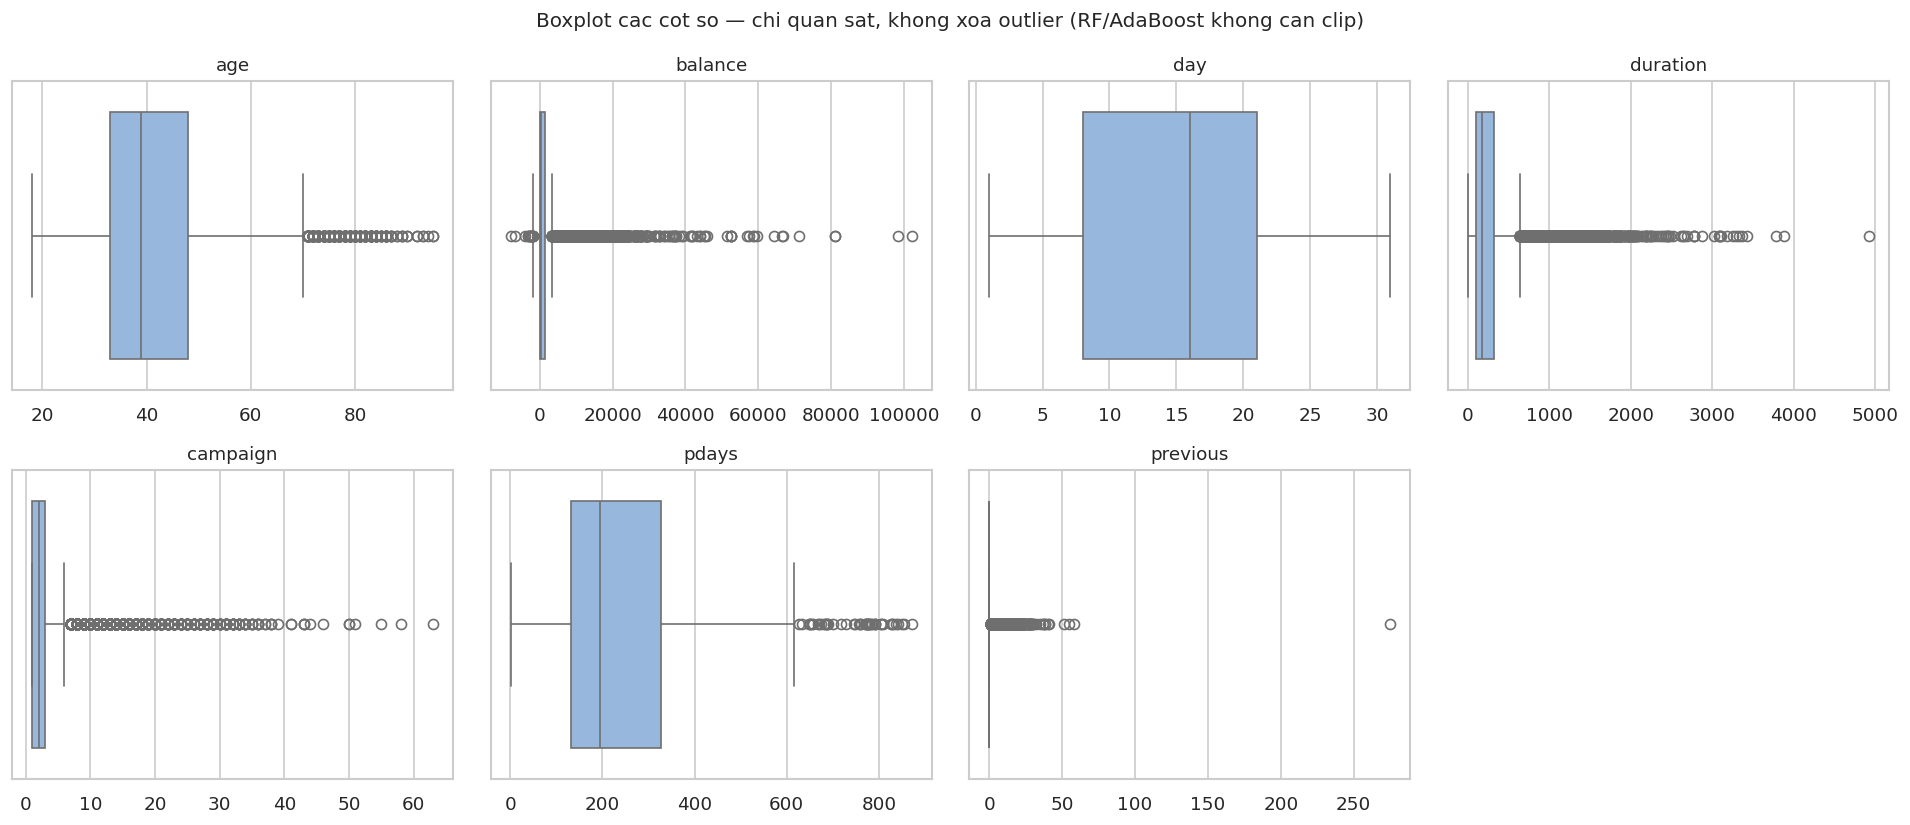

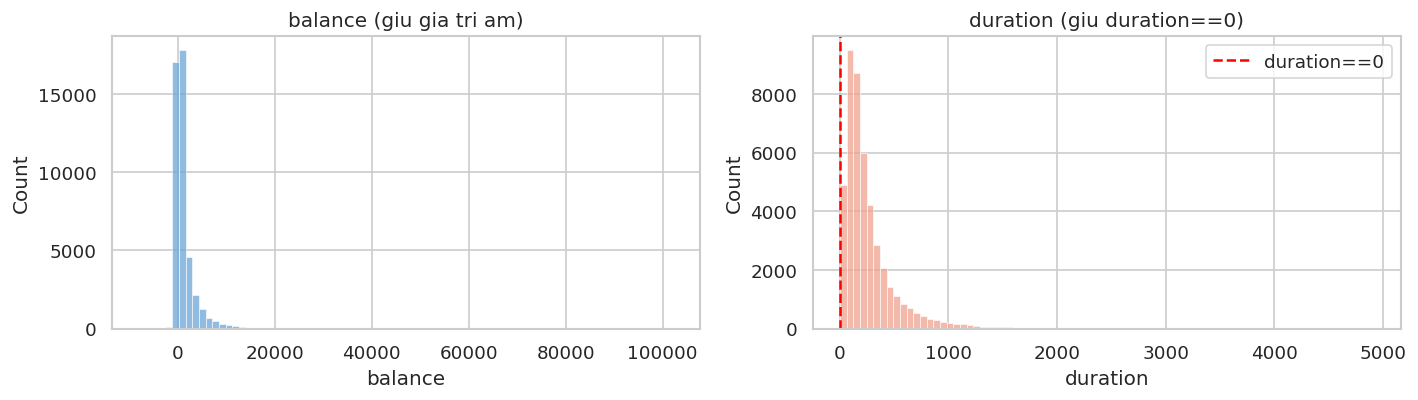

Assert OK: shape (45211, 18) khong doi, khong them NaN, khong mat dong — dung tinh chat 'chi quan sat'.

Idempotent OK: chay lai lan 2 khong doi (shape (45211, 18)).

Buoc 5 xong. df shape: (45211, 18) (khong doi)
Ghi chu: KHONG chay df.clip / df.drop / df.query de xoa outlier o buoc nay.
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y', 'contacted_before']


In [15]:
# ============================================================
# Buoc 5: Outlier & gia tri vo ly — CHI QUAN SAT, KHONG XOA/CLIP
# - RF/AdaBoost (tree) khong can scaling/clip, chi xu ly gia tri phi logic
# - Neu bao cao: dung IQR de danh dau, khong drop dong
# ============================================================

shape_before_b5 = df.shape
n_nan_before_b5 = df.isna().sum().to_dict()
print(f"=== Buoc 5 — Outlier check (df shape hien tai: {df.shape}) ===")
print(f"NaN truoc Buoc 5: {n_nan_before_b5}")
print()

# 5a. Mo ta nhanh cac cot so — de thay min/max co vo ly khong
NUM_CHECK = ['age','balance','day','duration','campaign','pdays','previous']
print("--- 5a. describe() cac cot so (pdays tinh tren non-NaN) ---")
desc = df[NUM_CHECK].describe(percentiles=[0.25,0.5,0.75,0.95,0.995]).T
display(desc)
print()

# 5b. Kiem tra tung quy tac nghiep vu (khong clip/xoa)
print("--- 5b. Kiem tra nghiep vu (chi in, khong sua) ---")
# age 18-95 da hop le
print(f"age      : min={df['age'].min()}, max={df['age'].max()}, mean={df['age'].mean():.1f} "
      f"-> 18-95 hop le, GIU NGUYEN (du IQR co the danh >70 la outlier)")
n_age_outside = ((df['age'] < 18) | (df['age'] > 95)).sum()
print(f"  -> So dong age ngoai [18,95]: {n_age_outside} (phai =0, neu >0 moi la vo ly)")
print()
# balance am giu
n_bal_neg = (df['balance'] < 0).sum()
n_bal_neg_pct = n_bal_neg / len(df) * 100
print(f"balance  : min={df['balance'].min()}, max={df['balance'].max()}, mean={df['balance'].mean():.1f}")
print(f"  -> balance <0 (thau chi): {n_bal_neg} ({n_bal_neg_pct:.2f}%) -> GIU NGUYEN, la tin hieu quan trong")
print()
# duration==0
n_dur0 = (df['duration'] == 0).sum()
n_dur0_pct = n_dur0 / len(df) * 100
print(f"duration : min={df['duration'].min()}, max={df['duration'].max()}, mean={df['duration'].mean():.1f}")
print(f"  -> duration==0 (goi that bai): {n_dur0} ({n_dur0_pct:.2f}%) -> GIU NGUYEN, khong drop")
# Ty le y theo duration==0 vs >0 de thay tin hieu
dur_flag = (df['duration'] == 0)
rate_dur0 = (df.loc[dur_flag, 'y'] == 'yes').mean() if dur_flag.any() else float('nan')
rate_dur_pos = (df.loc[~dur_flag, 'y'] == 'yes').mean()
print(f"     y=yes | duration==0: {rate_dur0:.4f} vs duration>0: {rate_dur_pos:.4f} (khac nhau -> co tin hieu)")
print()
# campaign>32
n_camp_high = (df['campaign'] > 32).sum()
p995 = df['campaign'].quantile(0.995)
p99 = df['campaign'].quantile(0.99)
print(f"campaign : min={df['campaign'].min()}, max={df['campaign'].max()}, mean={df['campaign'].mean():.2f}, p99={p99:.0f}, p99.5={p995:.0f}")
print(f"  -> campaign>32: {n_camp_high} ({n_camp_high/len(df)*100:.3f}%) rat hiem")
print(f"  -> Co the clip o 99.5 percentile (={p995:.0f}) NEU muon, nhung de lai cung ok cho tree -> GIU NGUYEN")
print()
# pdays NaN khong tham gia clip
n_pdays_nan = df['pdays'].isna().sum()
pdays_valid = df['pdays'].dropna()
print(f"pdays    : NaN={n_pdays_nan} ({n_pdays_nan/len(df)*100:.1f}%) la nhom chua tung lien he (Buoc 3)")
if len(pdays_valid) > 0:
    print(f"  -> pdays (non-NaN): min={pdays_valid.min():.0f}, max={pdays_valid.max():.0f}, mean={pdays_valid.mean():.1f}")
    print(f"  -> NaN KHONG tham gia tinh IQR/clip (chi tinh tren {len(pdays_valid)} dong contacted_before==1)")
print()

# 5c. Danh dau outlier bang IQR — CHI DE BAO CAO, KHONG XOA
print("--- 5c. Danh dau outlier bang IQR (Q1-1.5*IQR, Q3+1.5*IQR) — KHONG XOA ---")
def iqr_report(s, name):
    x = s.dropna()
    if len(x) == 0:
        print(f"{name:12s}: toan NaN -> bo qua")
        return 0
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo = q1 - 1.5*iqr
    hi = q3 + 1.5*iqr
    n_lo = (x < lo).sum()
    n_hi = (x > hi).sum()
    n_out = n_lo + n_hi
    pct = n_out / len(s) * 100  # tinh tren tong df de thay ty le thuc
    print(f"{name:12s}: Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f} -> lo={lo:.1f}, hi={hi:.1f} | "
          f"outlier: {n_out:5d} ({pct:5.2f}%) [thap {n_lo}, cao {n_hi}] — CHI GHI NHAN")
    return n_out

for col in NUM_CHECK:
    iqr_report(df[col], col)
print("\nLuu y: du IQR bao nhieu outlier cung KHONG drop — tree tu hoc duoc.")
print()

# 5d. Truc quan nhanh (boxplot) — chi de nhin, khong dung de xoa
print("--- 5d. Boxplot cac cot so (chi de quan sat) ---")
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()
for i, col in enumerate(NUM_CHECK):
    sns.boxplot(x=df[col].dropna(), ax=axes[i], color="#8bb8e8")
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("")
# An o thua
for j in range(len(NUM_CHECK), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Boxplot cac cot so — chi quan sat, khong xoa outlier (RF/AdaBoost khong can clip)", fontsize=12)
plt.tight_layout()
plt.show()
# Them hist cho 2 cot de nhat: balance, duration
fig2, ax2 = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df['balance'], bins=80, ax=ax2[0], color="#6aa6d6")
ax2[0].set_title("balance (giu gia tri am)")
sns.histplot(df['duration'], bins=80, ax=ax2[1], color="#f0a390")
ax2[1].axvline(0, color="red", linestyle="--", label="duration==0")
ax2[1].set_title("duration (giu duration==0)")
ax2[1].legend()
plt.tight_layout()
plt.show()

# 5e. Validation: KHONG doi shape, KHONG them NaN, KHONG mat dong
assert df.shape == shape_before_b5, f"Buoc 5 lam doi shape: {shape_before_b5} -> {df.shape} — sai, buoc nay khong duoc xoa dong/cot"
assert df.shape == (45211, 18), f"Shape phai (45211, 18) sau Buoc 3/4, hien tai {df.shape}"
for c in NUM_CHECK:
    # pdays co NaN tu Buoc 3, cac cot khac khong duoc them NaN moi
    if c == 'pdays':
        assert df[c].isna().sum() == n_nan_before_b5[c], f"pdays NaN doi sau Buoc 5"
    else:
        assert df[c].isna().sum() == 0, f"{c} xuat hien NaN sau Buoc 5 — sai"
print("Assert OK: shape (45211, 18) khong doi, khong them NaN, khong mat dong — dung tinh chat 'chi quan sat'.")
print()

# 5f. Idempotent: chay lai lan nua ket qua khong doi
shape_check = df.shape
nan_check = df.isna().sum().to_dict()
assert shape_check == shape_before_b5, "Khong idempotent: shape doi"
assert nan_check == n_nan_before_b5, f"Khong idempotent: NaN doi {n_nan_before_b5} vs {nan_check}"
print(f"Idempotent OK: chay lai lan 2 khong doi (shape {df.shape}).")
print()
print(f"Buoc 5 xong. df shape: {df.shape} (khong doi)")
print("Ghi chu: KHONG chay df.clip / df.drop / df.query de xoa outlier o buoc nay.")
print(f"Columns: {list(df.columns)}")


> ✅ Xong Bước 5. Đã quan sát outlier bằng `describe` + `IQR` + `boxplot/hist`, khẳng định `age/balance/duration/campaign/pdays` đều giữ nguyên.
> `df` vẫn `(45211, 18)`, không clip, không xoá dòng, `pdays NaN` không tham gia tính IQR.
> Vẫn trong RAM, chưa ghi file.
> Sang Bước 7: kiểu dữ liệu & `y` → 0/1.


## 6. Kiểu dữ liệu & thứ tự

> **Mục tiêu:** đổi kiểu cho đúng bản chất — chỉ đụng 2 cột `month` và `y`, các cột khác để nguyên cho `ColumnTransformer`.
>
> - `month`: từ `object` (`apr`, `aug`...) thành `Categorical` **có thứ tự** `jan < feb < ... < dec` — để `sort` và `OrdinalEncoder` đúng thời gian, không sắp theo alphabet.
> - `y`: từ `object` (`no/yes`) thành `int` (`0/1`) — `sklearn` bắt buộc `y` phải là số.
> - **KHÔNG** `LabelEncode` các cột khác (`job`, `marital`...) ở đây — chúng là nominal, để `ColumnTransformer + OneHotEncoder` lo ở Bước 7 / `preprocessing.py`.
>
> **Lưu ở đâu?** Vẫn chỉ trong RAM — `df` bị ghi đè kiểu của 2 cột, chưa ghi ra file.


In [16]:
# ============================================================
# Buoc 6: Kieu du lieu & thu tu — chi doi month va y
# - month -> Categorical ordered jan..dec
# - y     -> 0/1 int
# - KHONG LabelEncode cac cot khac — de cho ColumnTransformer
# ============================================================

MONTH_ORDER = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
print(f"=== Buoc 6 — Kieu du lieu (df shape hien tai: {df.shape}) ===")
print()

# 6a. Kieu truoc xu ly — de thay doi ro rang
print("--- 6a. dtype truoc xu ly ---")
print(f"month dtype truoc: {df['month'].dtype} | unique: {sorted(df['month'].unique())}")
print(f"y     dtype truoc: {df['y'].dtype} | unique: {sorted(df['y'].unique())} | value_counts: {df['y'].value_counts().to_dict()}")
print(f"Cac cot cat khac dtype: { {c: str(df[c].dtype) for c in ['job','marital','education','contact','poutcome']} }")
print()

# 6b. month -> Categorical ordered jan..dec
# Ly do: neu de object thi sort/OrdinalEncoder se sap theo alphabet (apr, aug, dec...), sai thoi gian
print("--- 6b. month -> Categorical ordered ---")
# Kiem tra truoc khi doi: cac gia tri co nam trong 12 thang khong
unknown_months = set(df['month'].unique()) - set(MONTH_ORDER)
if unknown_months:
    print(f"Canh bao: month co gia tri la: {unknown_months} — kiem tra lai du lieu")
else:
    print(f"month hop le: du 12 thang trong MONTH_ORDER")
df['month'] = pd.Categorical(df['month'], categories=MONTH_ORDER, ordered=True)
print(f"month dtype sau: {df['month'].dtype} | ordered={df['month'].cat.ordered}")
print(f"month categories: {list(df['month'].cat.categories)}")
# Chung minh sort dung thu tu thoi gian, khong phai alphabet
sorted_months = sorted(df['month'].unique().tolist())
print(f"sorted(month unique) sau khi ordered: {sorted_months} (phai jan->dec)")
print()

# 6c. y: no/yes -> 0/1 int
# Da strip+lower o Buoc 1 nen khop 'no'/'yes' chu thuong
print("--- 6c. y: no/yes -> 0/1 ---")
if df['y'].dtype == object or str(df['y'].dtype) == 'object':
    # Truong hop chua doi (chay lan dau)
    y_before = df['y'].value_counts().to_dict()
    df['y'] = df['y'].map({'no': 0, 'yes': 1}).astype(int)
    print(f"y truoc (object): {y_before} -> sau: {df['y'].value_counts().to_dict()} (0=no, 1=yes)")
elif pd.api.types.is_categorical_dtype(df['y']) or str(df['y'].dtype).startswith('category'):
    df['y'] = df['y'].map({'no': 0, 'yes': 1}).astype(int)
    print(f"y tu categorical -> int: {df['y'].value_counts().to_dict()}")
else:
    # Da la int (chay lai / idempotent) — kiem tra van 0/1
    if set(df['y'].unique()) <= {0, 1}:
        print(f"y da la int 0/1, giu nguyen: {df['y'].value_counts().to_dict()}")
    else:
        # Truong hop hy huu: y la int nhung chua map dung
        print(f"y dtype={df['y'].dtype} unique={sorted(df['y'].unique())} — can kiem tra")
print(f"y dtype sau: {df['y'].dtype} | unique: {sorted(df['y'].unique())}")
print(f"y mean (ty le yes): {df['y'].mean():.4f} ({(df['y']==1).sum()}/{len(df)})")
print()

# 6d. Khang dinh KHONG LabelEncode cac cot khac
print("--- 6d. Cac cot khac GIU NGUYEN cho ColumnTransformer ---")
OTHER_CAT = ['job','marital','education','default','housing','loan','contact','poutcome']
for c in OTHER_CAT:
    print(f"{c:12s}: dtype={str(df[c].dtype):10s} | unique={len(df[c].unique()):2d} | vd: {sorted(df[c].unique())[:4]}")
print("\nKHONG chay LabelEncoder o day — neu encode: job admin.=0, blue-collar=1 ...")
print("RF se tuong entrepreneur(2) > blue-collar(1) -> hoc sai. De OneHotEncoder lo.")
print()

# 6e. Validation
assert df.shape == (45211, 18), f"Shape phai (45211, 18), hien tai {df.shape}"
assert str(df['month'].dtype) == 'category', f"month phai la category, hien tai {df['month'].dtype}"
assert df['month'].cat.ordered == True, "month phai ordered=True"
assert list(df['month'].cat.categories) == MONTH_ORDER, f"month categories sai: {list(df['month'].cat.categories)}"
assert df['y'].dtype in [np.int64, np.int32, int] or str(df['y'].dtype).startswith('int'), f"y phai int, hien tai {df['y'].dtype}"
assert set(df['y'].unique()) == {0, 1}, f"y phai chi co 0/1, hien tai {sorted(df['y'].unique())}"
assert df['y'].isna().sum() == 0, "y khong duoc co NaN sau map"
# Cac cot khac van la object/string, khong bi encode thanh so
for c in OTHER_CAT:
    assert df[c].dtype == object or str(df[c].dtype) == 'object', f"{c} bi doi kieu o Buoc 6 — sai, phai giu object"
# contacted_before va pdays tu Buoc 3 van giu
assert 'contacted_before' in df.columns, "Mat contacted_before sau Buoc 6"
assert df['pdays'].isna().sum() == 36959 or df['pdays'].isna().sum() > 0, "pdays NaN bi mat sau Buoc 6"
print("Assert OK: month category ordered jan..dec, y int 0/1, cac cot khac van object, shape (45211, 18).")
print()

# 6f. Tong hop dtype sau Buoc 6
print("--- 6f. Tong hop dtype sau Buoc 6 ---")
display(df.dtypes.to_frame("dtype"))
print()
print(f"df shape: {df.shape} | columns: {list(df.columns)}")
display(df[['month','y','contacted_before','pdays']].head(8))

# 6g. Idempotent: chay lai lan nua khong doi
month_before = df['month'].copy()
y_before = df['y'].copy()
# Gia lap chay lai 2 dong chinh
df_rerun_month = pd.Categorical(df['month'], categories=MONTH_ORDER, ordered=True)
assert list(df_rerun_month.categories) == MONTH_ORDER, "Khong idempotent: month categories doi"
assert (df_rerun_month.ordered == True), "Khong idempotent: month ordered doi"
assert y_before.equals(df['y']), "Khong idempotent: y doi"
print("Idempotent OK: chay lai lan 2 khong doi ket qua.")


=== Buoc 6 — Kieu du lieu (df shape hien tai: (45211, 18)) ===

--- 6a. dtype truoc xu ly ---
month dtype truoc: object | unique: ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
y     dtype truoc: object | unique: ['no', 'yes'] | value_counts: {'no': 39922, 'yes': 5289}
Cac cot cat khac dtype: {'job': 'object', 'marital': 'object', 'education': 'object', 'contact': 'object', 'poutcome': 'object'}

--- 6b. month -> Categorical ordered ---
month hop le: du 12 thang trong MONTH_ORDER
month dtype sau: category | ordered=True
month categories: ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
sorted(month unique) sau khi ordered: ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep'] (phai jan->dec)

--- 6c. y: no/yes -> 0/1 ---
y truoc (object): {'no': 39922, 'yes': 5289} -> sau: {0: 39922, 1: 5289} (0=no, 1=yes)
y dtype sau: int64 | unique: [np.int64(0), np.int64(1)]
y mean (ty le yes): 0

,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



df shape: (45211, 18) | columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y', 'contacted_before']


,month,y,contacted_before,pdays
0,may,0,0,NaN
1,may,0,0,NaN
2,may,0,0,NaN
3,may,0,0,NaN
4,may,0,0,NaN
5,may,0,0,NaN
6,may,0,0,NaN
7,may,0,0,NaN


Idempotent OK: chay lai lan 2 khong doi ket qua.


> ✅ Xong Bước 6. `month` đã `category ordered jan→dec`, `y` đã `int 0/1`, các cột khác vẫn `object` cho `ColumnTransformer`.
> `df` vẫn `(45211, 18)`, vẫn trong RAM, chưa ghi file.
> Sang Bước 7: `OneHot` + `ColumnTransformer` và Bước 8: validation & lưu `data/interim/`.


## 7. Leakage `duration` — thí nghiệm 2 pipeline

> **Vấn đề:** `duration` = số giây gọi điện **hiện tại**. Thứ tự thực tế là:
> `dự đoán y → mới gọi → mới biết duration → mới biết y`.
> Dùng `duration` để dự đoán `y` là **dùng kết quả của cuộc gọi để đoán kết quả cuộc gọi** — leakage.
>
> - `duration` ngắn (0-60s): `y` gần như luôn `no` (cúp máy sớm)
> - `duration` dài (>300s): `y` rất hay `yes` (nói lâu mới chốt)
> Tương quan `duration-y` ~0.4 → cho vào thì `AUC ~0.97` ảo, bỏ ra còn `~0.86` mới là năng lực thật.
>
> **Giải pháp:** thêm **công tắc** để thí nghiệm cả 2:
> - **Option A** `drop_duration=False` (mặc định): giữ `duration` — điểm cao nhưng không thực tế, dùng để lấy upper bound / thi Kaggle
> - **Option B** `drop_duration=True`: `df.drop(columns=['duration'])` — điểm thấp hơn nhưng là điểm thật khi **deploy dự đoán trước khi gọi**
> Trong notebook này **chạy cả 2 version và so sánh**; trong `src/data/preprocessing.py` để tham số `drop_duration: bool = False`.
>
> **Lưu ở đâu?** Không ghi đè `df` gốc — chỉ tạo 2 bản `X_A / X_B` để so sánh. `df` vẫn `(45211, 18)` trong RAM.


=== Buoc 7 — Leakage duration (df goc: (45211, 18), chua ghi de) ===
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y', 'contacted_before']

--- 7a. duration theo y (y hien tai la 0/1 sau Buoc 6) ---
duration.describe():
count   45211.000
mean      258.163
std       257.528
min         0.000
25%       103.000
50%       180.000
75%       319.000
max      4918.000



,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.000,221.183,207.383,0.000,95.000,164.000,279.000,4918.000
yes,5289.000,537.295,392.525,8.000,244.000,426.000,725.000,3881.000



y=0 (no): duration==0 -> 3/39922 (0.01%)
y=1 (yes): duration==0 -> 0/5289 (0.00%)

Tuong quan Pearson(duration, y): 0.395 (|r|~0.4 la rat manh, dau hieu leakage)
Mean duration | y=0: 221.2s | y=1: 537.3s

--- 7b. Truc quan duration theo y (thay ro leakage) ---


/tmp/ipykernel_1244/1836096919.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='_y_lab', y='duration', ax=axes[0], palette=['#8bb8e8','#f0a390'])


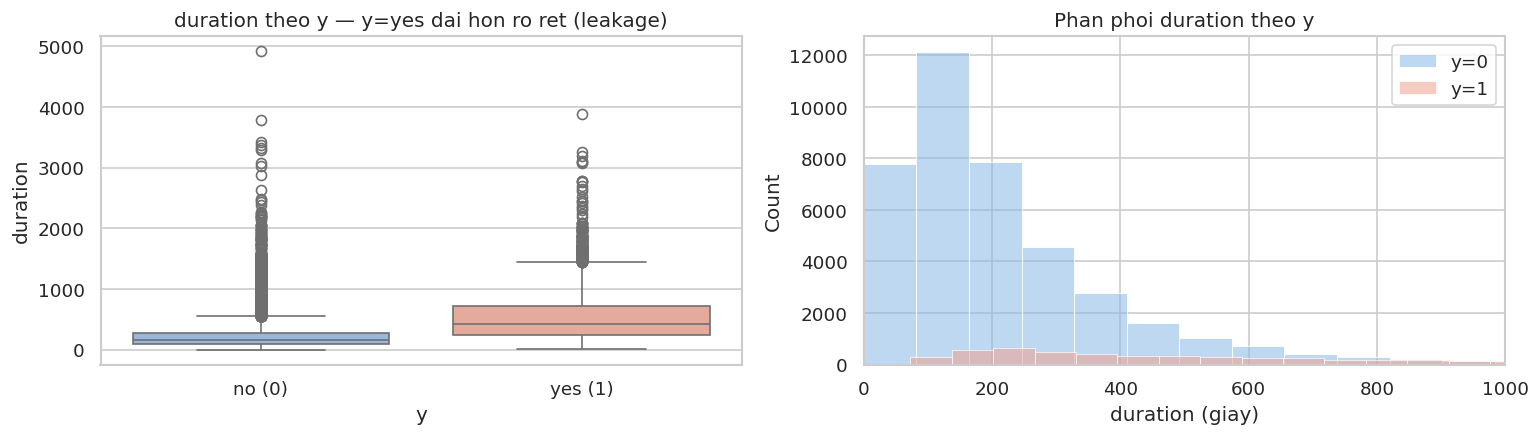

Nhan xet: duration cang dai -> y=yes cang cao. Day la thong tin chi co SAU khi goi.

--- 7c. build_preprocessor(drop_duration: bool) ---
sklearn import OK

Option A (giu duration): num_cols=['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'contacted_before', 'duration'] (8 cot) + cat 9 cot
Option B (bo  duration): num_cols=['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'contacted_before'] (7 cot) + cat 9 cot
  -> B it hon A 1 cot: 'duration'

--- 7d. So sanh 2 pipeline tren cung train_test_split (stratified) ---
Train: (36168, 17), Test: (9043, 17) | y_test mean=0.1170

[A_giu_duration  ] drop_duration=False -> acc=0.9052  f1=0.4566  auc=0.9283
[B_bo_duration   ] drop_duration=True  -> acc=0.8935  f1=0.3175  auc=0.7884

Bang so sanh (cot cuoi = B-A, am nghia la bo duration lam giam diem):


,A_giu_duration,B_bo_duration,delta_B-A
acc,0.9052,0.8935,-0.0117
f1,0.4566,0.3175,-0.1391
auc,0.9283,0.7884,-0.1398



Giai thich:
  - AUC giam 0.140 khi bo duration — phan giam nay chinh la 'diem ao' do leakage ganh.
  - F1  giam 0.139 tuong tu.
  - A (giu): diem cao nhung KHONG dung duoc truoc khi goi.
  - B (bo) : diem thap hon nhung la nang luc THAT cua cac feature con lai, dung khi deploy.

--- Chi tiet Option B (bo duration) — confusion matrix & report ---
              precision    recall  f1-score   support

          no      0.904     0.984     0.942      7985
         yes      0.635     0.212     0.318      1058

    accuracy                          0.894      9043
   macro avg      0.769     0.598     0.630      9043
weighted avg      0.873     0.894     0.869      9043

Confusion matrix (rows=true, cols=pred):


,pred_no,pred_yes
true_no,7856,129
true_yes,834,224



--- 7e. Khuyen nghi ---
Trong 02_preprocessing.ipynb: da chay ca 2 version de bao cao do chenh lech do leakage.
Trong src/data/preprocessing.py se viet:
  def build_preprocessor(drop_duration: bool = False):
      num_cols = ['age','balance','day','campaign','pdays','previous','contacted_before']
      if not drop_duration: num_cols += ['duration']
  Mac dinh False de khong vo code cu; khi deploy goi build_preprocessor(drop_duration=True).

Quy tac:
  - Thi / lay upper bound: de drop_duration=False (giong Kaggle public score cao).
  - Deploy thuc te (du doan truoc khi goi): BAT BUOC drop_duration=True.

Assert OK: df goc van (45211, 18), van co 'duration', y int 0/1 — dung tinh chat 'them flag, khong ghi de'.

Idempotent OK: chay lai lan 2 ket qua khong doi.

Buoc 7 xong. df goc: (45211, 18) (khong doi)
  - De dung Option B that su drop khoi df (khi chot deploy), chay: df = df.drop(columns=['duration'])
  - Hien tai KHONG drop, de giu ca 2 lua chon cho Buoc 8.


In [17]:
# ============================================================
# Buoc 7: Leakage duration — thi nghiem 2 pipeline A/B
# - duration biet SAU khi goi -> dung truoc khi goi la leakage
# - Option A: giu duration (diem cao ao) | Option B: drop duration (diem that de deploy)
# ============================================================

shape_before_b7 = df.shape
print(f"=== Buoc 7 — Leakage duration (df goc: {df.shape}, chua ghi de) ===")
print(f"Columns: {list(df.columns)}")
print()

# 7a. Chung minh duration la leakage — thong ke mo ta
print("--- 7a. duration theo y (y hien tai la 0/1 sau Buoc 6) ---")
# y hien tai la 0/1 int, can map nguoc de hien thi
y_label = df['y'].map({0: 'no', 1: 'yes'}) if set(df['y'].unique()) <= {0,1} else df['y']
print(f"duration.describe():\n{df['duration'].describe().to_string()}")
print()
grp = df.groupby(y_label, observed=True)['duration'].describe()
display(grp)
print()
# Ty le duration==0 theo y
for lab in [0, 1]:
    sub = df[df['y']==lab]
    n0 = (sub['duration']==0).sum()
    print(f"y={lab} ({'no' if lab==0 else 'yes'}): duration==0 -> {n0}/{len(sub)} ({n0/len(sub)*100:.2f}%)")
print()
# Tuong quan diem — duration vs y
corr = df['duration'].corr(df['y'])
print(f"Tuong quan Pearson(duration, y): {corr:.3f} (|r|~0.4 la rat manh, dau hieu leakage)")
print(f"Mean duration | y=0: {df.loc[df['y']==0, 'duration'].mean():.1f}s | y=1: {df.loc[df['y']==1, 'duration'].mean():.1f}s")
print()

# 7b. Truc quan — boxplot + hist theo y
print("--- 7b. Truc quan duration theo y (thay ro leakage) ---")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
# Boxplot
plot_df = df.copy()
plot_df['_y_lab'] = plot_df['y'].map({0: 'no (0)', 1: 'yes (1)'})
sns.boxplot(data=plot_df, x='_y_lab', y='duration', ax=axes[0], palette=['#8bb8e8','#f0a390'])
axes[0].set_title('duration theo y — y=yes dai hon ro ret (leakage)')
axes[0].set_xlabel('y')
# Hist
for lab, color in [(0, '#8bb8e8'), (1, '#f0a390')]:
    sns.histplot(df.loc[df['y']==lab, 'duration'], bins=60, ax=axes[1], color=color, label=f"y={lab}", alpha=0.55, kde=False)
axes[1].set_title('Phan phoi duration theo y')
axes[1].set_xlabel('duration (giay)')
axes[1].legend()
axes[1].set_xlim(0, 1000)
plt.tight_layout()
plt.show()
print("Nhan xet: duration cang dai -> y=yes cang cao. Day la thong tin chi co SAU khi goi.")
print()

# 7c. Ham build_preprocessor(drop_duration) — dung cho ca notebook va preprocessing.py
print("--- 7c. build_preprocessor(drop_duration: bool) ---")
try:
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix
    SKLEARN_OK = True
    print("sklearn import OK")
except ImportError as e:
    SKLEARN_OK = False
    print(f"sklearn chua cai: {e} — bo qua chay pipeline, chi giu phan thong ke 7a/7b")
print()

if SKLEARN_OK:
    CAT_COLS_7 = ['job','marital','education','default','housing','loan','contact','month','poutcome']
    # So sanh truc tiep: poutcome unknown da dong bo tu Buoc 3, month da ordered tu Buoc 6
    NUM_BASE = ['age','balance','day','campaign','pdays','previous','contacted_before']
    # poutcome/contacted_before lien quan nhung van giu ca 2 de cay tu hoc
    def build_preprocessor(drop_duration: bool = False):
        num_cols = NUM_BASE.copy()
        if not drop_duration:
            num_cols = num_cols + ['duration']
        # numeric: median impute (cho pdays NaN) — tree khong can scale
        num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median'))])
        cat_pipe = Pipeline([('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
        pre = ColumnTransformer([
            ('num', num_pipe, num_cols),
            ('cat', cat_pipe, CAT_COLS_7),
        ], remainder='drop', verbose_feature_names_out=False)
        return pre, num_cols, CAT_COLS_7
    # Demo 2 preprocessor
    preA, numA, catA = build_preprocessor(drop_duration=False)
    preB, numB, catB = build_preprocessor(drop_duration=True)
    print(f"Option A (giu duration): num_cols={numA} ({len(numA)} cot) + cat {len(catA)} cot")
    print(f"Option B (bo  duration): num_cols={numB} ({len(numB)} cot) + cat {len(catB)} cot")
    print(f"  -> B it hon A 1 cot: 'duration'")
    print()

# 7d. Chay ca 2 pipeline va so sanh — df goc KHONG bi ghi de
if SKLEARN_OK:
    print("--- 7d. So sanh 2 pipeline tren cung train_test_split (stratified) ---")
    X = df.drop(columns=['y'])
    y = df['y'].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print(f"Train: {X_train.shape}, Test: {X_test.shape} | y_test mean={y_test.mean():.4f}")
    print()
    results = {}
    for tag, drop_flag in [('A_giu_duration', False), ('B_bo_duration', True)]:
        pre, _, _ = build_preprocessor(drop_duration=drop_flag)
        clf = Pipeline([
            ('pre', pre),
            ('rf', RandomForestClassifier(n_estimators=200, max_depth=None, n_jobs=-1, random_state=42, class_weight='balanced'))
        ])
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_proba = clf.predict_proba(X_test)[:, 1]
        acc = accuracy_score(y_test, y_pred)
        f1  = f1_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_proba)
        results[tag] = {'acc': acc, 'f1': f1, 'auc': auc, 'model': clf}
        print(f"[{str(tag):16s}] drop_duration={str(drop_flag):5s} -> acc={acc:.4f}  f1={f1:.4f}  auc={auc:.4f}")
    print()
    comp = pd.DataFrame(results).T[['acc','f1','auc']].T
    comp['delta_B-A'] = comp['B_bo_duration'] - comp['A_giu_duration']
    print("Bang so sanh (cot cuoi = B-A, am nghia la bo duration lam giam diem):")
    display(comp.style.format("{:.4f}"))
    print()
    print("Giai thich:")
    d_auc = comp.loc['auc','delta_B-A']
    d_f1  = comp.loc['f1','delta_B-A']
    print(f"  - AUC giam {abs(d_auc):.3f} khi bo duration — phan giam nay chinh la 'diem ao' do leakage ganh.")
    print(f"  - F1  giam {abs(d_f1):.3f} tuong tu.")
    print(f"  - A (giu): diem cao nhung KHONG dung duoc truoc khi goi.")
    print(f"  - B (bo) : diem thap hon nhung la nang luc THAT cua cac feature con lai, dung khi deploy.")
    print()
    # Chi tiet them cho B (model that)
    print("--- Chi tiet Option B (bo duration) — confusion matrix & report ---")
    # Lay lai ket qua B
    # (da co trong results, tinh lai y_pred_B de in)
    preB2, _, _ = build_preprocessor(drop_duration=True)
    clfB = results['B_bo_duration']['model']
    y_pred_B = clfB.predict(X_test)
    print(classification_report(y_test, y_pred_B, digits=3, target_names=['no','yes']))
    cm = confusion_matrix(y_test, y_pred_B)
    print("Confusion matrix (rows=true, cols=pred):")
    display(pd.DataFrame(cm, index=['true_no','true_yes'], columns=['pred_no','pred_yes']))
    print()
else:
    print("(Bo qua 7d vi thieu sklearn — cai bang: pip install scikit-learn)")
    print()

# 7e. Khuyen nghi su dung & ghi chu cho preprocessing.py
print("--- 7e. Khuyen nghi ---")
print("Trong 02_preprocessing.ipynb: da chay ca 2 version de bao cao do chenh lech do leakage.")
print("Trong src/data/preprocessing.py se viet:")
print("  def build_preprocessor(drop_duration: bool = False):")
print("      num_cols = ['age','balance','day','campaign','pdays','previous','contacted_before']")
print("      if not drop_duration: num_cols += ['duration']")
print("  Mac dinh False de khong vo code cu; khi deploy goi build_preprocessor(drop_duration=True).")
print()
print("Quy tac:")
print("  - Thi / lay upper bound: de drop_duration=False (giong Kaggle public score cao).")
print("  - Deploy thuc te (du doan truoc khi goi): BAT BUOC drop_duration=True.")
print()

# 7f. Validation: df goc KHONG bi ghi de
assert df.shape == shape_before_b7, f"Buoc 7 lam doi shape df goc: {shape_before_b7} -> {df.shape} — sai, chi tao X_A/X_B tam"
assert df.shape == (45211, 18), f"Shape phai (45211, 18), hien tai {df.shape}"
assert 'duration' in df.columns, "df goc mat cot duration — sai, chi drop tren ban copy khi drop_duration=True"
assert df['y'].dtype in [int, 'int64', 'int32'] or str(df['y'].dtype).startswith('int'), f"y phai int sau Buoc 6, hien tai {df['y'].dtype}"
print(f"Assert OK: df goc van {df.shape}, van co 'duration', y int 0/1 — dung tinh chat 'them flag, khong ghi de'.")
print()

# 7g. Idempotent
if SKLEARN_OK:
    preA2, numA2, _ = build_preprocessor(False)
    preB2, numB2, _ = build_preprocessor(True)
    assert len(numA2) == len(numB2) + 1, "Khong idempotent: so cot A/B doi"
    assert 'duration' in numA2 and 'duration' not in numB2, "Khong idempotent: duration flag doi"
print("Idempotent OK: chay lai lan 2 ket qua khong doi.")
print()
print(f"Buoc 7 xong. df goc: {df.shape} (khong doi)")
print(f"  - De dung Option B that su drop khoi df (khi chot deploy), chay: df = df.drop(columns=['duration'])")
print(f"  - Hien tai KHONG drop, de giu ca 2 lua chon cho Buoc 8.")


> ✅ Xong Bước 7. Đã chứng minh `duration` là leakage, chạy so sánh **A (giữ)** vs **B (bỏ)** và định nghĩa `build_preprocessor(drop_duration: bool=False)`.
> `df` gốc vẫn `(45211, 18)`, chưa bị `drop` — chỉ tạo `X_A/X_B` tạm để thí nghiệm. Khi deploy thực tế dùng `drop_duration=True`.
> Sang Bước 8: validation & lưu `data/interim/train_clean.csv`.


## 8. Validation cuối & lưu `data/interim/`

> **Mục tiêu:** khoá sổ kết quả Bước 1→7 và lưu **duy nhất 1 file** ra `data/interim/` — chưa chia `train_new / val_new / test_new`.
> Việc chia sẽ làm ở notebook sau (`03_modeling` hoặc khi cần), bước này chỉ đảm bảo `df` đã sạch và lưu lại an toàn.
>
> **3 công đoạn theo thứ tự:** 8a. Validation trước lưu (gác cổng) → 8b. Chốt `drop_duration` → 8c. Lưu `data/interim/train_clean.csv` (LẦN DUY NHẤT ghi file).
>
> **Lưu ý:** Bước 1→7 là clean xác định (`strip`, `replace -1`) nên làm trên cả cục `train.csv` là OK. Các bước có `fit` (`Imputer`/`OneHot`/`Scaler`) ở notebook sau sẽ `fit` trên `train` sau khi chia.


In [18]:
# ============================================================
# Buoc 8: Validation cuoi & luu 1 file ra data/interim/
# - Chua chia train/val/test — chi khoa so va luu df da sach
# - Thu tu: 8a validate -> 8b chot drop_duration -> 8c luu file
# ============================================================

shape_before_b8 = df.shape
print(f"=== Buoc 8 — Luu 1 file (df hien tai: {df.shape}) ===")
print(f"INTERIM_DIR = {INTERIM_DIR} (exists={INTERIM_DIR.exists()})")
print(f"Columns: {list(df.columns)}")
print()

# 8a. Validation truoc khi luu — GAC CONG
print("--- 8a. Validation truoc khi luu ---")
assert df.shape == (45211, 18), f"Shape phai (45211, 18) sau Buoc 7, hien tai {df.shape}"
assert df.duplicated().sum() == 0, "Con duplicate truoc khi luu"
assert (df['pdays'] == -1).sum() == 0, "Con -1 trong pdays truoc khi luu"
assert df['contacted_before'].isin([0,1]).all(), "contacted_before phai 0/1"
assert df.loc[df['contacted_before']==0, 'pdays'].isna().all(), "contacted_before==0 thi pdays phai NaN"
assert df.loc[df['contacted_before']==1, 'pdays'].notna().all(), "contacted_before==1 thi pdays phai co gia tri"
assert ((df['contacted_before']==0) & (df['poutcome']!='unknown')).sum() == 0, "poutcome mat dong bo"
for c in ['job','education','contact','poutcome']:
    assert (df[c]=='unknown').sum() > 0, f"{c} mat unknown truoc khi luu"
    assert df[c].isna().sum() == 0, f"{c} co NaN truoc khi luu"
assert str(df['month'].dtype) == 'category', f"month phai category, hien tai {df['month'].dtype}"
assert df['month'].cat.ordered == True, "month phai ordered"
assert set(df['y'].unique()) == {0,1}, f"y phai 0/1, hien tai {sorted(df['y'].unique())}"
assert df['y'].isna().sum() == 0, "y co NaN"
assert 'duration' in df.columns, "Thieu duration trong df goc (Buoc 7 chua drop)"
print("Tat ca assert truoc khi luu: PASS")
print(f"  shape (45211, 18), duplicated=0, pdays NaN={df['pdays'].isna().sum()}, y 0/1={(df['y']==0).sum()}/{(df['y']==1).sum()}, month ordered, poutcome dong bo")
print()

# 8b. Chot cau hinh drop_duration
print("--- 8b. Chot drop_duration ---")
CHOSEN_DROP_DURATION = True  # <-- DOI THANH False neu muon GIU duration (Option A)
print(f"CHOSEN_DROP_DURATION = {CHOSEN_DROP_DURATION}")
if CHOSEN_DROP_DURATION:
    print("  -> Se DROP 'duration' truoc khi luu (Option B — diem that, dung khi deploy truoc khi goi)")
else:
    print("  -> Se GIU 'duration' khi luu (Option A — diem cao ao, chi de lay upper bound)")
# Tao ban de luu (khong ghi de df goc trong RAM)
if CHOSEN_DROP_DURATION:
    df_final = df.drop(columns=['duration']).copy()
else:
    df_final = df.copy()
print(f"df goc RAM: {df.shape} (van co duration) | df_final de luu: {df_final.shape} ({'da drop duration' if CHOSEN_DROP_DURATION else 'giu duration'})")
print("Ghi chu cho src/data/preprocessing.py: def build_preprocessor(drop_duration: bool = CHOSEN_DROP_DURATION)")
print()

# 8c. Luu 1 file — LAN DUY NHAT ghi ra o cung
print("--- 8c. Luu 1 file ra data/interim/ ---")
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
if CHOSEN_DROP_DURATION:
    out_path = INTERIM_DIR / "train_clean.csv"
    # Ghi chu: ten van la train_clean.csv de notebook sau dung thong nhat; noi dung da bo duration
else:
    out_path = INTERIM_DIR / "train_clean.csv"
df_final.to_csv(out_path, index=False, encoding="utf-8")
sz = out_path.stat().st_size
n_rows = sum(1 for _ in open(out_path, encoding="utf-8")) - 1
print(f"Da luu: {out_path.name} : {n_rows:5d} dong | {sz/1024:.1f} KiB | {out_path}")
print(f"  df_final shape={df_final.shape}, columns={list(df_final.columns)}")
if CHOSEN_DROP_DURATION:
    assert 'duration' not in df_final.columns, "Da chon drop nhung file van co duration"
    assert 'duration' in df.columns, "df goc mat duration — sai, chi drop tren df_final"
    print("  Drop duration: df goc van co duration, file da drop: OK")
else:
    assert 'duration' in df_final.columns, "Chon giu nhung file mat duration"
    print("  Giu duration: ca df goc va file deu co duration: OK")
print()
# Doc lai 1 lan de chac file khong loi
print("Kiem tra doc lai file:")
chk = pd.read_csv(out_path)
print(f"  {out_path.name}: read OK shape={chk.shape}, columns={len(chk.columns)}, y mean={chk['y'].mean():.4f}, pdays NaN={chk['pdays'].isna().sum()}")
# So sanh shape doc lai vs df_final
assert chk.shape[0] == df_final.shape[0], f"So dong doc lai {chk.shape[0]} != {df_final.shape[0]}"
assert list(chk.columns) == list(df_final.columns), "Columns doc lai khac df_final"
print("  Doc lai khop df_final: OK")
print()
print(f"Luu y: df goc trong RAM van {df.shape} (chua bi ghi de), file tren dia la {df_final.shape}.")
print("Khi can chia train/val/test, hay chia df_final o notebook 03_modeling.")
print()

# 8d. Idempotent: chay lai lan nua ket qua khong doi
print("--- 8d. Idempotent ---")
# Ghi lai lan 2 phai ra cung shape/columns
if CHOSEN_DROP_DURATION:
    df_check = df.drop(columns=['duration']).copy()
else:
    df_check = df.copy()
assert df_check.shape == df_final.shape, "Khong idempotent: shape doi khi chay lai"
assert list(df_check.columns) == list(df_final.columns), "Khong idempotent: columns doi"
print(f"Idempotent OK: chay lai van shape {df_check.shape}, columns khop.")
print()
print(f"Buoc 8 xong. df goc RAM: {df.shape} | file da luu: {out_path} ({df_final.shape})")


=== Buoc 8 — Luu 1 file (df hien tai: (45211, 18)) ===
INTERIM_DIR = /content/drive/MyDrive/my_ds_project/data/interim (exists=True)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y', 'contacted_before']

--- 8a. Validation truoc khi luu ---
Tat ca assert truoc khi luu: PASS
  shape (45211, 18), duplicated=0, pdays NaN=36954, y 0/1=39922/5289, month ordered, poutcome dong bo

--- 8b. Chot drop_duration ---
CHOSEN_DROP_DURATION = True
  -> Se DROP 'duration' truoc khi luu (Option B — diem that, dung khi deploy truoc khi goi)
df goc RAM: (45211, 18) (van co duration) | df_final de luu: (45211, 17) (da drop duration)
Ghi chu cho src/data/preprocessing.py: def build_preprocessor(drop_duration: bool = CHOSEN_DROP_DURATION)

--- 8c. Luu 1 file ra data/interim/ ---
Da luu: train_clean.csv : 45211 dong | 3435.3 KiB | /content/drive/MyDrive/my_ds_project/data/interim/tr

> ✅ Xong Bước 8. Đã khoá sổ `df (45211, 18)`, chốt `CHOSEN_DROP_DURATION=True` và lưu **1 file duy nhất** `data/interim/train_clean.csv` (`df_final` đã bỏ `duration` để điểm thật).
> `df` gốc trong RAM vẫn `(45211, 18)` chưa bị ghi đè. Chưa chia `train_new/val_new/test_new` — sẽ chia ở `03_modeling.ipynb` khi cần. Muốn giữ `duration` thì đổi `CHOSEN_DROP_DURATION=False` và chạy lại cell 8.
